# PHA Predictor — Entregable I

**Proyecto:** clasificación binaria de asteroides potencialmente peligrosos (*Potentially Hazardous Asteroids*, PHA).
**Integrantes:** Eliana Maria Brand Agudelo, Jilberth Ferney Alzate Castaño, Juan Esteban Gil Quintero.
**Datos:** [NASA – Nearest Earth Objects (Kaggle)](https://www.kaggle.com/datasets/sameepvani/nasa-nearest-earth-objects) → `neo.csv` está incluido en el repositorio, junto a este notebook (licencia CC0: dominio público).

Estructura (la misma del informe `reporte.pdf`):

1. **Descripción del problema:** A. contexto y utilidad de una solución basada en ML; B. composición de la base de datos y análisis exploratorio; C. paradigma de aprendizaje.
2. **Estado del arte:** cuatro trabajos previos.

Este notebook reproduce las cifras, tablas y figuras del informe (`reporte.pdf`). No escribe archivos: todo se muestra en pantalla.

In [1]:
import os, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, cross_val_predict
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

# --- Rutas -----------------------------------------------------------------
candidates = [os.environ.get("NEO_CSV", ""), "neo.csv", "data/neo.csv"]
DATA_PATH = next((Path(p) for p in candidates if p and Path(p).exists()), None)
assert DATA_PATH is not None, "No se encontró neo.csv junto al notebook. Si falta, descárgalo desde el enlace de Kaggle."

# --- Estilo de figuras -----------------------------------------------------
plt.rcParams.update({"font.size": 8, "axes.titlesize": 8, "axes.labelsize": 8,
                     "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7,
                     "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False})
C0, C1 = "#4C72B0", "#C44E52"   # no peligroso / peligroso
print("Datos:", DATA_PATH)

Datos: neo.csv


# 1. Descripción del problema

## 1.A Contexto y utilidad de una solución basada en ML

Un **asteroide potencialmente peligroso (PHA)** es un objeto cercano a la Tierra (NEO) con distancia mínima de intersección orbital (MOID) $\le 0.05$ ua (≈ $7.5\times10^{6}$ km) y magnitud absoluta $H \le 22$ (≈ 140 m de diámetro) según el
[CNEOS de la NASA](https://cneos.jpl.nasa.gov/about/neo_groups.html).

Un clasificador automático sirve para **priorizar** el seguimiento: con pocas variables fáciles de obtener (magnitud absoluta, diámetro estimado, velocidad relativa y distancia de paso) permite ordenar qué objetos conviene observar con más detalle y qué variables explican la etiqueta.
No reemplaza el cálculo oficial del MOID: como la etiqueta se define con $H$ y MOID y este último **no está en la base**, el modelo aproxima una regla determinista con variables parcialmente informativas, lo que limita el desempeño alcanzable.

## 1.B Composición de la base de datos

Base *NASA – Nearest Earth Objects* (Kaggle, S. Vani): **90 836 filas y 10 variables**. Cada fila es una *aproximación* de un asteroide a la Tierra; hay solo **27 423 asteroides distintos**.

| Variable | Significado | Tipo (unidad) | Tratamiento |
|---|---|---|---|
| `id` | Identificador del asteroide | Entero | Grupo para la validación |
| `name` | Designación provisional | Texto | Excluida |
| `est_diameter_min` | Diámetro estimado mínimo | Continua (km) | $\log_{10}$ + z-score (redundante con $H$) |
| `est_diameter_max` | Diámetro estimado máximo | Continua (km) | $\log_{10}$ + z-score (redundante con $H$) |
| `relative_velocity` | Velocidad relativa a la Tierra | Continua (km/h, asumida) | z-score |
| `miss_distance` | Distancia de paso a la Tierra | Continua (km) | z-score |
| `orbiting_body` | Cuerpo orbitado (siempre *Earth*) | Categórica | Constante: se elimina |
| `sentry_object` | Incluido en el sistema Sentry | Booleana | Constante: se elimina |
| `absolute_magnitude` | Magnitud absoluta $H$ (brillo intrínseco) | Continua (mag) | z-score |
| `hazardous` | Etiqueta PHA (variable objetivo) | Booleana | `False→0`, `True→1` |

Las unidades de diámetros y distancia de paso están indicadas en la descripción de Kaggle; la velocidad no declara unidad. Las tres se **validan** en la sección 1.B.3 contra aproximaciones publicadas por la NASA/JPL: la velocidad está en km/h y la distancia de paso en km.

**Faltantes e imputación:** no hay valores faltantes ni filas duplicadas (se verifica abajo), por lo que no se requiere imputación. Si aparecieran, se imputarían con la mediana calculada solo con el conjunto de entrenamiento de cada pliegue.

### 1.B.1 Carga y visión general

In [2]:
df = pd.read_csv(DATA_PATH)
print("Dimensión:", df.shape)
display(df.head())
display(df.dtypes.to_frame("dtype").T)

Dimensión: (90836, 10)


,id,name,est_diameter_min,est_diameter_max,relative_velocity,miss_distance,orbiting_body,sentry_object,absolute_magnitude,hazardous
0,2162635,162635 (2000 SS164),1.198271,2.679415,13569.249224,5.483974e+07,Earth,False,16.73,False
1,2277475,277475 (2005 WK4),0.265800,0.594347,73588.726663,6.143813e+07,Earth,False,20.00,True
2,2512244,512244 (2015 YE18),0.722030,1.614507,114258.692129,4.979872e+07,Earth,False,17.83,False
3,3596030,(2012 BV13),0.096506,0.215794,24764.303138,2.543497e+07,Earth,False,22.20,False
4,3667127,(2014 GE35),0.255009,0.570217,42737.733765,4.627557e+07,Earth,False,20.09,True


,id,name,est_diameter_min,est_diameter_max,relative_velocity,miss_distance,orbiting_body,sentry_object,absolute_magnitude,hazardous
dtype,int64,str,float64,float64,float64,float64,str,bool,float64,bool


### 1.B.2 Calidad de los datos: faltantes, duplicados y variables constantes

In [3]:
print("Valores faltantes por columna:\n", df.isna().sum().to_string())
print("\nFilas duplicadas (todas las columnas):", df.duplicated().sum())
print("Filas duplicadas (sin 'id'):", df.drop(columns="id").duplicated().sum())
print("\nValores únicos por columna:\n", df.nunique().to_string())
print("\norbiting_body:", df.orbiting_body.unique(), "| sentry_object:", df.sentry_object.unique())

Valores faltantes por columna:
 id                    0
name                  0
est_diameter_min      0
est_diameter_max      0
relative_velocity     0
miss_distance         0
orbiting_body         0
sentry_object         0
absolute_magnitude    0
hazardous             0

Filas duplicadas (todas las columnas): 0
Filas duplicadas (sin 'id'): 0



Valores únicos por columna:
 id                    27423
name                  27423
est_diameter_min       1638
est_diameter_max       1638
relative_velocity     90828
miss_distance         90536
orbiting_body             1
sentry_object             1
absolute_magnitude     1638
hazardous                 2

orbiting_body: <StringArray>
['Earth']
Length: 1, dtype: str | sentry_object: [False]


**Hallazgos.** No hay valores faltantes ni filas duplicadas → no se requiere imputación.
`orbiting_body` (siempre *Earth*) y `sentry_object` (siempre *False*) son constantes y no aportan información.

### 1.B.3 Validación de las unidades de medida

Kaggle indica km para diámetros y distancia de paso, pero no la unidad de la velocidad. Se validan con tres argumentos:

1. **Aproximaciones documentadas por la NASA/JPL.** Se buscan en la base tres pasos bien conocidos y se comparan con las cifras publicadas (2012 DA14 el 15-feb-2013, 2001 FO32 el 21-mar-2021 y 433 Eros el 31-ene-2012).
2. **Rango físico.** Si la velocidad estuviera en km/s su máximo ($2.4\times10^{5}$) sería el 79 % de la velocidad de la luz; en km/h equivale a 0.06–66 km/s, con mediana de 12 km/s, que es el rango típico de los encuentros con la Tierra.
3. **Tope de la base.** Leída en km, la distancia de paso máxima es exactamente 0.5 ua (0.499998 ua): un corte de selección redondo en unidades astronómicas, que no aparecería si la columna estuviera en otra unidad.

Los diámetros se validan en la sección 1.B.6: coinciden con la fórmula estándar $D=1329/\sqrt{p}\,10^{-H/5}$ km.

In [4]:
AU_KM = 149597870.7          # 1 ua en km
R_TIERRA = 6371              # radio medio de la Tierra (km); la base mide desde el centro de la Tierra
# Cifras publicadas (NASA/JPL y prensa que las cita); ver referencias en el informe
ref = pd.DataFrame([
    ("367943 Duende (2012 DA14)", "2013-02-15", "27 700 km sobre la superficie", 27700 + R_TIERRA, "7.8 km/s", 7.8 * 3600),
    ("231937 (2001 FO32)",        "2021-03-21", "≈ 2 millones de km",             2.0e6,            "≈ 124 000 km/h", 124000),
    ("433 Eros (A898 PA)",        "2012-01-31", "26 729 000 km",                  26.729e6,         "—", np.nan)],
    columns=["Asteroide", "Fecha", "Distancia publicada", "dist_ref_km", "Velocidad publicada", "vel_ref_kmh"])
rows = []
for _, r in ref.iterrows():
    d = df[df.name == r["Asteroide"]]
    fila = d.loc[(d.miss_distance - r["dist_ref_km"]).abs().idxmin()]      # la aproximación de la base más cercana a la publicada
    rows.append({"Asteroide": r["Asteroide"], "Fecha": r["Fecha"],
                 "miss_distance (base)": f"{fila.miss_distance:,.0f}", "Distancia publicada": r["Distancia publicada"],
                 "relative_velocity (base)": f"{fila.relative_velocity:,.0f}",
                 "= km/s si la base está en km/h": round(fila.relative_velocity / 3600, 2),
                 "Velocidad publicada": r["Velocidad publicada"]})
display(pd.DataFrame(rows))
v = df.relative_velocity
print("Velocidad, interpretada en km/h -> km/s:  mín %.2f | mediana %.2f | máx %.2f" % (v.min()/3600, v.median()/3600, v.max()/3600))
print("Si estuviera en km/s, el máximo sería %.0f %% de la velocidad de la luz" % (100 * v.max() / 299792.458))
print("Distancia de paso máxima: %.6f ua (corte redondo en 0.5 ua)" % (df.miss_distance.max() / AU_KM))

,Asteroide,Fecha,miss_distance (base),Distancia publicada,relative_velocity (base),= km/s si la base está en km/h,Velocidad publicada
0,367943 Duende (2012 DA14),2013-02-15,"34,053",27 700 km sobre la superficie,"28,152",7.82,7.8 km/s
1,231937 (2001 FO32),2021-03-21,"2,016,392",≈ 2 millones de km,"123,887",34.41,≈ 124 000 km/h
2,433 Eros (A898 PA),2012-01-31,"26,729,521",26 729 000 km,"21,403",5.95,—


Velocidad, interpretada en km/h -> km/s:  mín 0.06 | mediana 12.28 | máx 65.83
Si estuviera en km/s, el máximo sería 79 % de la velocidad de la luz
Distancia de paso máxima: 0.499998 ua (corte redondo en 0.5 ua)


### 1.B.4 Estructura por asteroide: un mismo objeto aparece varias veces

In [5]:
n_per_id = df.groupby("id").size()
per_id = df.groupby("id").agg(hazardous=("hazardous", "first"),
                              n_labels=("hazardous", "nunique"),
                              n_H=("absolute_magnitude", "nunique"))
print("Filas:", len(df), "| asteroides únicos (id):", df.id.nunique())
print(n_per_id.describe().round(2).to_string())
print("\nAsteroides con etiqueta inconsistente entre filas:", int((per_id.n_labels > 1).sum()))
print("Asteroides con más de un valor de H:", int((per_id.n_H > 1).sum()))
print("Proporción de filas cuyo asteroide aparece >= 2 veces: %.3f" % df.id.map(df.id.value_counts()).ge(2).mean())

Filas: 90836 | asteroides únicos (id): 27423
count    27423.00
mean         3.31
std          3.41
min          1.00
25%          1.00
50%          2.00
75%          4.00
max         43.00

Asteroides con etiqueta inconsistente entre filas: 0
Asteroides con más de un valor de H: 0
Proporción de filas cuyo asteroide aparece >= 2 veces: 0.873


**Hallazgo clave.** Las 90 836 filas corresponden a solo 27 423 asteroides: cada fila es una *aproximación a la Tierra*.
La etiqueta y H son propias del asteroide (no cambian entre filas) → si se parte el dataset al azar, el mismo asteroide
cae en entrenamiento y prueba (**fuga de datos**). Se usará validación agrupada por `id`.

### 1.B.5 Balance de clases

Por fila:       {False: 81996, True: 8840} {False: 0.9027, True: 0.0973}
Por asteroide:  {False: 25250, True: 2173} {False: 0.9208, True: 0.0792}
Exactitud de un clasificador trivial (todo 'no peligroso'): 0.9027


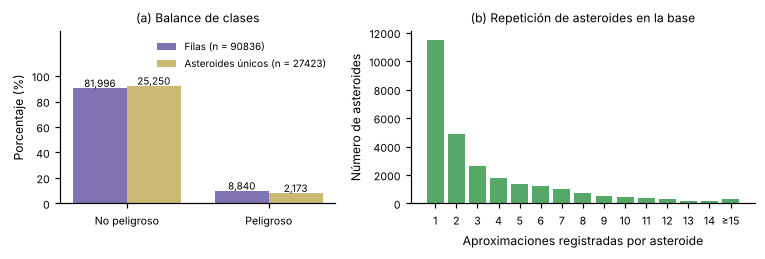

In [6]:
rows_cnt = df.hazardous.value_counts().sort_index()          # False, True
ast_cnt  = per_id.hazardous.value_counts().sort_index()
print("Por fila:      ", rows_cnt.to_dict(), (rows_cnt / rows_cnt.sum()).round(4).to_dict())
print("Por asteroide: ", ast_cnt.to_dict(),  (ast_cnt / ast_cnt.sum()).round(4).to_dict())
print("Exactitud de un clasificador trivial (todo 'no peligroso'): %.4f" % (rows_cnt[False] / rows_cnt.sum()))

fig, ax = plt.subplots(1, 2, figsize=(7.0, 2.4), gridspec_kw={"width_ratios": [1, 1.25]})
x, w = np.arange(2), 0.38
pr, pa = 100 * rows_cnt / rows_cnt.sum(), 100 * ast_cnt / ast_cnt.sum()
b1 = ax[0].bar(x - w/2, pr.values, w, color="#8172B3", label="Filas (n = %d)" % len(df))
b2 = ax[0].bar(x + w/2, pa.values, w, color="#CCB974", label="Asteroides únicos (n = %d)" % len(per_id))
for bars, cnt in ((b1, rows_cnt), (b2, ast_cnt)):
    for r, c in zip(bars, cnt.values):
        ax[0].text(r.get_x() + r.get_width()/2, r.get_height() + 1.2, f"{c:,}", ha="center", fontsize=6.5)
ax[0].set_xticks(x); ax[0].set_xticklabels(["No peligroso", "Peligroso"])
ax[0].set_ylabel("Porcentaje (%)"); ax[0].set_ylim(0, 135); ax[0].set_yticks(range(0, 101, 20)); ax[0].legend(frameon=False, loc="upper right", fontsize=6.5)
ax[0].set_title("(a) Balance de clases")

cap = 15
vc = n_per_id.clip(upper=cap).value_counts().sort_index()
ax[1].bar(vc.index, vc.values, color="#55A868")
ax[1].set_xticks(range(1, cap + 1)); ax[1].set_xticklabels([str(i) for i in range(1, cap)] + [f"≥{cap}"])
ax[1].set_xlabel("Aproximaciones registradas por asteroide"); ax[1].set_ylabel("Número de asteroides")
ax[1].set_title("(b) Repetición de asteroides en la base")
fig.tight_layout(); plt.show()

### 1.B.6 Redundancia entre variables: los diámetros son función de H

In [7]:
# Relación estándar entre diámetro, albedo (p) y magnitud absoluta H:  D = 1329/sqrt(p) * 10^(-H/5)  [km]
H = df.absolute_magnitude
d_max_hat = 1329 / np.sqrt(0.05) * 10 ** (-H / 5)    # albedo mínimo 0.05  -> diámetro máximo
d_min_hat = 1329 / np.sqrt(0.25) * 10 ** (-H / 5)    # albedo máximo 0.25  -> diámetro mínimo
print("Error relativo máx. est_diameter_max vs fórmula: %.2e" % (abs(d_max_hat - df.est_diameter_max) / df.est_diameter_max).max())
print("Error relativo máx. est_diameter_min vs fórmula: %.2e" % (abs(d_min_hat - df.est_diameter_min) / df.est_diameter_min).max())
print("Razón max/min: %.6f   (sqrt(5) = %.6f)" % ((df.est_diameter_max / df.est_diameter_min).mean(), np.sqrt(5)))
print("Correlación de Pearson entre log10(est_diameter_max) y H: %.6f" % np.corrcoef(np.log10(df.est_diameter_max), H)[0, 1])

Error relativo máx. est_diameter_max vs fórmula: 1.86e-08
Error relativo máx. est_diameter_min vs fórmula: 5.26e-08
Razón max/min: 2.236068   (sqrt(5) = 2.236068)
Correlación de Pearson entre log10(est_diameter_max) y H: -1.000000


**Hallazgo.** `est_diameter_min` y `est_diameter_max` se obtienen exactamente de `absolute_magnitude` con albedos 0.25 y 0.05
(error relativo ≈ 1e-8). En la práctica hay **3 variables físicamente independientes**: H, velocidad relativa y distancia de paso.

### 1.B.7 Estadísticos descriptivos

In [8]:
num = ["est_diameter_min", "est_diameter_max", "relative_velocity", "miss_distance", "absolute_magnitude"]
desc = df[num].describe().T
desc["median"] = df[num].median()
desc["skew"] = [skew(df[c]) for c in num]
display(desc[["min", "50%", "mean", "std", "max", "skew"]].round(4))


,min,50%,mean,std,max,skew
est_diameter_min,0.0006,4.840000e-02,1.274000e-01,2.985000e-01,3.789260e+01,41.1393
est_diameter_max,0.0014,1.082000e-01,2.849000e-01,6.675000e-01,8.473050e+01,41.1393
relative_velocity,203.3464,4.419012e+04,4.806692e+04,2.529330e+04,2.369901e+05,0.9051
miss_distance,6745.5325,3.784658e+07,3.706655e+07,2.235204e+07,7.479865e+07,-0.0427
absolute_magnitude,9.2300,2.370000e+01,2.352710e+01,2.894100e+00,3.320000e+01,-0.1374


### 1.B.8 Distribuciones por clase

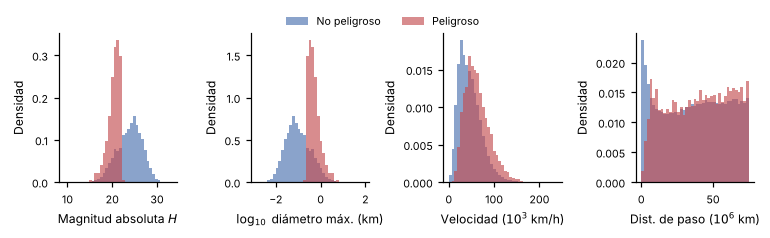

           absolute_magnitude  relative_velocity  miss_distance
hazardous                                                      
False                    24.1            42565.5     37487452.4
True                     20.6            58658.0     40983720.7


In [9]:
y = df.hazardous.astype(int)
panels = [("Magnitud absoluta $H$", df.absolute_magnitude, None),
          ("$\\log_{10}$ diámetro máx. (km)", np.log10(df.est_diameter_max), None),
          ("Velocidad ($10^3$ km/h)", df.relative_velocity / 1e3, None),
          ("Dist. de paso ($10^6$ km)", df.miss_distance / 1e6, None)]
fig, axes = plt.subplots(1, 4, figsize=(7.0, 2.0))
for ax, (lab, v, _) in zip(axes, panels):
    bins = np.linspace(v.min(), v.max(), 40)
    ax.hist(v[y == 0], bins=bins, density=True, alpha=.65, color=C0, label="No peligroso")
    ax.hist(v[y == 1], bins=bins, density=True, alpha=.65, color=C1, label="Peligroso")
    ax.set_xlabel(lab); ax.set_ylabel("Densidad")
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.07))
fig.tight_layout(); plt.show()
print(df.groupby("hazardous")[["absolute_magnitude", "relative_velocity", "miss_distance"]].median().round(1))

### 1.B.9 Correlaciones

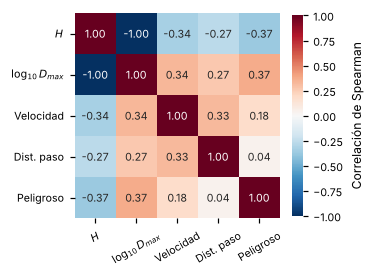

In [10]:
tmp = pd.DataFrame({"$H$": df.absolute_magnitude,
                    "$\\log_{10}D_{max}$": np.log10(df.est_diameter_max),
                    "Velocidad": df.relative_velocity,
                    "Dist. paso": df.miss_distance,
                    "Peligroso": y})
corr = tmp.corr(method="spearman")
fig, ax = plt.subplots(figsize=(3.4, 2.9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True,
            cbar_kws={"label": "Correlación de Spearman", "shrink": .8}, annot_kws={"size": 7}, ax=ax)
ax.tick_params(axis="x", rotation=30)
fig.tight_layout(); plt.show()

### 1.B.10 Tasa de peligrosidad vs. magnitud absoluta

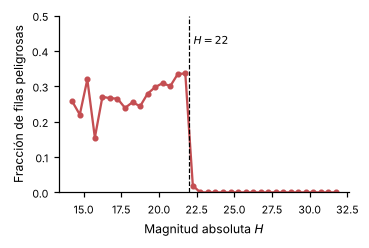

P(peligroso | H <= 22) = 0.3007   P(peligroso | H > 22) = 0.0015
Filas peligrosas con H > 22: 90 de 8840
Filas con H <= 22: 29101 | de ellas NO peligrosas: 20351


In [11]:
bins = np.arange(9, 33.5, 0.5)
cut = pd.cut(df.absolute_magnitude, bins)
g = df.groupby(cut, observed=True).hazardous.agg(["mean", "size"])
g = g[g["size"] >= 30]
mid = np.array([iv.mid for iv in g.index])
fig, ax = plt.subplots(figsize=(3.4, 2.3))
ax.plot(mid, g["mean"], "o-", ms=3, color=C1)
ax.axvline(22, ls="--", color="k", lw=.8); ax.text(22.3, 0.42, "$H=22$", fontsize=7)
ax.set_xlabel("Magnitud absoluta $H$"); ax.set_ylabel("Fracción de filas peligrosas")
ax.set_ylim(0, 0.5)
fig.tight_layout(); plt.show()
print("P(peligroso | H <= 22) = %.4f   P(peligroso | H > 22) = %.4f" % (y[H <= 22].mean(), y[H > 22].mean()))
print("Filas peligrosas con H > 22:", int(((y == 1) & (H > 22)).sum()), "de", int(y.sum()))
print("Filas con H <= 22:", int((H <= 22).sum()), "| de ellas NO peligrosas:", int(((H <= 22) & (y == 0)).sum()))

**Interpretación.** La definición oficial de PHA exige simultáneamente $H \le 22$ (≈ más de 140 m) y una distancia mínima de intersección orbital
(MOID) $\le 0.05$ ua. La base contiene $H$ pero **no el MOID**: $H \le 22$ es casi condición necesaria (solo 90 filas peligrosas con $H > 22$)
pero no suficiente (≈ 70 % de las filas con $H \le 22$ son no peligrosas). Esto fija un techo de desempeño para cualquier modelo.

### Figura 1 del informe: balance de clases y fracción de PHA según $H$

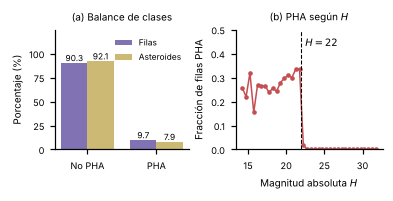

In [12]:
with plt.rc_context({"font.size": 6.5, "axes.titlesize": 6.5, "axes.labelsize": 6.5, "xtick.labelsize": 6,
                     "ytick.labelsize": 6, "legend.fontsize": 5.5}):
    fig, ax = plt.subplots(1, 2, figsize=(3.45, 1.7), gridspec_kw={"width_ratios": [1, 1.1]})
    x, w = np.arange(2), 0.38
    pr, pa = 100 * rows_cnt / rows_cnt.sum(), 100 * ast_cnt / ast_cnt.sum()
    ax[0].bar(x - w/2, pr.values, w, color="#8172B3", label="Filas")
    ax[0].bar(x + w/2, pa.values, w, color="#CCB974", label="Asteroides")
    for xi, v in zip(x - w/2, pr.values): ax[0].text(xi, v + 2, f"{v:.1f}", ha="center", fontsize=5.5)
    for xi, v in zip(x + w/2, pa.values): ax[0].text(xi, v + 2, f"{v:.1f}", ha="center", fontsize=5.5)
    ax[0].set_xticks(x); ax[0].set_xticklabels(["No PHA", "PHA"])
    ax[0].set_ylabel("Porcentaje (%)"); ax[0].set_ylim(0, 125); ax[0].set_yticks(range(0, 101, 25))
    ax[0].legend(frameon=False, loc="upper right"); ax[0].set_title("(a) Balance de clases")
    ax[1].plot(mid, g["mean"], "o-", ms=2, lw=1, color=C1)
    ax[1].axvline(22, ls="--", color="k", lw=.7); ax[1].text(22.5, 0.43, "$H=22$")
    ax[1].set_xlabel("Magnitud absoluta $H$"); ax[1].set_ylabel("Fracción de filas PHA")
    ax[1].set_ylim(0, 0.5); ax[1].set_title("(b) PHA según $H$")
    fig.tight_layout(pad=0.4); plt.show()

### 1.B.11 Poder discriminativo univariado

In [13]:
uni = {c: roc_auc_score(y, df[c]) for c in ["absolute_magnitude", "est_diameter_max", "relative_velocity", "miss_distance"]}
for c, a in uni.items():
    print(f"{c:20s} AUC univariado = {max(a, 1 - a):.3f}")

absolute_magnitude   AUC univariado = 0.865
est_diameter_max     AUC univariado = 0.865
relative_velocity    AUC univariado = 0.679
miss_distance        AUC univariado = 0.542


### 1.B.12 Evidencia preliminar de fuga de datos: partición aleatoria vs. agrupada por asteroide
Modelos base con hiperparámetros por defecto, 5 pliegues. **No** es la evaluación final (Entregable II); solo cuantifica el efecto de ignorar el `id`.

In [14]:
X = pd.DataFrame({"log_d": np.log10(df.est_diameter_max), "vel": df.relative_velocity, "dist": df.miss_distance})
splits = {"Aleatoria estratificada": (StratifiedKFold(5, shuffle=True, random_state=SEED), {}),
          "Agrupada por id":        (StratifiedGroupKFold(5, shuffle=True, random_state=SEED), {"groups": df.id})}
models = {"Regresión logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced")),
          "Random Forest": RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=SEED)}
res = []
for sname, (cv, kw) in splits.items():
    for mname, m in models.items():
        p = cross_val_predict(m, X, y, cv=cv, method="predict_proba", **kw)[:, 1]
        res.append({"Partición": sname, "Modelo": mname, "ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p)})
res = pd.DataFrame(res).round(3)
display(res)

,Partición,Modelo,ROC-AUC,PR-AUC
0,Aleatoria estratificada,Regresión logística,0.873,0.294
1,Aleatoria estratificada,Random Forest,0.927,0.570
2,Agrupada por id,Regresión logística,0.873,0.293
3,Agrupada por id,Random Forest,0.904,0.483


### 1.B.13 Plan de preprocesamiento propuesto (se ajusta *dentro* de cada pliegue en el Entregable II)
| Variable | Tratamiento |
|---|---|
| `id`, `name` | Identificadores: se excluyen como predictores; `id` se usa como **grupo** para la validación. |
| `orbiting_body`, `sentry_object` | Constantes → se eliminan. |
| `absolute_magnitude`, `relative_velocity`, `miss_distance` | Estandarización (z-score) ajustada solo con el entrenamiento. |
| `est_diameter_min/max` | Redundantes con H (log-lineales); se evalúan/eliminan en la sección de reducción de dimensión. |
| `hazardous` | Objetivo: `False→0`, `True→1`. |
| Desbalance (9.7 %) | `class_weight`, ponderación/umbral y métricas robustas (PR-AUC, F1, recall de la clase positiva). |

## 1.C Paradigma de aprendizaje

Se plantea un problema de **aprendizaje supervisado**, en la modalidad de **clasificación binaria**: dado $\mathcal{D}=\{(\mathbf{x}_i,y_i)\}_{i=1}^{N}$ con $y_i\in\{0,1\}$, se estima $P(y=1\mid\mathbf{x})$ y se decide con $\hat y=\mathbb{1}[f(\mathbf{x})\ge\tau]$.

Justificación:

- Todas las filas tienen etiqueta confiable (la clasificación oficial de la NASA), así que un enfoque no supervisado desaprovecharía información y no hay datos sin etiquetar que justifiquen uno semisupervisado.
- La salida es discreta (PHA / no PHA), por lo que no es un problema de regresión.
- Los costos son asimétricos: no detectar un PHA es más grave que una falsa alarma. Por eso se estimarán probabilidades y se ajustará el umbral $\tau$.

Implicaciones para el diseño experimental: validación estratificada y **agrupada por `id`**; desbalance tratado con pesos de clase o umbral (cualquier remuestreo solo sobre el entrenamiento); y métricas centradas en la clase positiva (precisión, recall, $F_1$, PR-AUC), con la exactitud solo como referencia.

# 2. Estado del arte

Se revisaron **cuatro** trabajos sobre clasificación de PHA con ML; los dos primeros usan esta misma base. En todos el paradigma es **aprendizaje supervisado (clasificación binaria)**.

| Ref. | Datos | Técnicas | Validación | Métricas | Resultados |
|---|---|---|---|---|---|
| [3] Malakouti, Menhaj, Suratgar, *MethodsX* 11, 102337 (2023) | Kaggle; cita la base *NASA asteroids classification* pero describe 90 836 filas y 10 columnas con las mismas variables que esta base | Extra Trees, Random Forest (RF), LightGBM, Gradient Boosting, AdaBoost; GridSearchCV; eliminación de atípicos y normalización Min-Max | 80 % con validación cruzada de 10 pliegues (GridSearchCV); el 20 % restante se divide en validación y prueba (10 %/10 %); también 70/15/15 y 60/20/20. No describe partición agrupada | AUC por clase y AUC micro y macro | RF: AUC 0.94 por clase, micro 0.98, macro 0.94; Extra Trees 0.93; LightGBM 0.92; GB 0.92; AdaBoost 0.91 (partición 80/10/10). El texto interpreta el AUC como exactitud |
| [4] Wang, *HSET* 39, 201–208 (2023) | **Misma base** (90 836 filas, 10 columnas); se descartan `orbiting_body` y `sentry_object` | Regresión logística, KNN, RF, árbol de decisión (DT), Naive Bayes multinomial, Gradient Boosting (GB), Voting (RF+DT+GB) | No describe la partición; las métricas casi simétricas por clase y su matriz de confusión sugieren una prueba balanceada (inferencia nuestra) | Exactitud, precisión, recall, $F_1$, matriz de confusión | Exactitud: RF 0.95, Voting 0.94, DT 0.93, GB 0.89 (recall PHA 0.99), KNN 0.79, LR 0.58, NB 0.56 |
| [5] Buana et al., arXiv:2409.02150 (2024) | Kaggle *Asteroid Dataset* (958 524 filas) y NeoWs (362 717 filas; ≈ 13 % positivos) | LR, KNN, SVC, RF, CatBoost; MLP, DNN, Conv2D, RNN, LSTM; bootstrapping y SMOTE | Partición 80:20; el balanceo y el escalado se describen antes de la partición | Exactitud, precisión, recall, $F_1$, ROC-AUC | RF y CatBoost: $F_1$ = AUC = 0.99 en ambas bases; DNN ≈ 0.99 de exactitud de validación (NeoWs) |
| [6] Baimam, arXiv:2504.18605 (2025) | JPL Small-Body Database vía Kaggle (958 524 asteroides; 0.22 % PHA; > 85 % de faltantes en diámetro y albedo) | Red neuronal de grafos (grafo kNN, $k=5$, convolución y atención); SMOTE y Focal Loss; comparada con MLP, GAT e Isolation Forest | Partición 80:20 estratificada; SMOTE solo en entrenamiento | Precisión, recall, $F_1$, AUC | Exactitud 0.99, AUC 0.99; clase PHA: precisión 0.24, recall 0.78, $F_1$ 0.37 |

**Métricas.** Precisión $P=\frac{TP}{TP+FP}$, recall $R=\frac{TP}{TP+FN}$, $F_1=\frac{2PR}{P+R}$ y $\mathrm{AUC}=\Pr[s(\mathbf{x}^{+})>s(\mathbf{x}^{-})]$. En [3] se usan además el AUC macro, $\frac{1}{K}\sum_{k=1}^{K}\mathrm{AUC}_k$ con $K=2$, y el AUC micro, calculado sobre una sola curva ROC que agrupa las decisiones de todas las clases.

**Síntesis.**

1. Los ensambles de árboles (RF y boosting) dan los mejores resultados en tres de los cuatro trabajos.
2. Los resultados no son comparables: [3] reporta AUC pero lo interpreta como exactitud; [4] reporta exactitud sobre una prueba que parece balanceada; [6] muestra que una exactitud de 0.99 convive con una precisión de 0.24 en la clase PHA. En nuestra base un clasificador trivial logra 90.27 % de exactitud.
3. Ningún trabajo con esta base describe validación agrupada por asteroide; el AUC de 0.94 de [3] es del orden del 0.927 que obtuvimos con partición aleatoria (0.904 agrupada, sección 1.B.12). En [5] el balanceo se describe antes de la partición.
4. [3] reporta `miss_distance` como la variable más importante (≈ 0.30), pese a que aquí es la menos discriminativa de las tres variables independientes (AUC 0.542); el Entregable II (sección 4.1) lo revisa: sí pesa en conjunto con las demás variables.
5. [6] usa parámetros orbitales (excentricidad, semieje mayor, perihelio) ausentes en esta base.

**Referencias.**

[1] NASA/JPL CNEOS, "NEO groups," https://cneos.jpl.nasa.gov/about/neo_groups.html (consultado el 2 oct. 2026).
[2] S. Vani, "NASA – Nearest Earth Objects," Kaggle, 2022. https://www.kaggle.com/datasets/sameepvani/nasa-nearest-earth-objects (consultado el 2 oct. 2026).
[3] S. M. Malakouti, M. B. Menhaj y A. A. Suratgar, "Machine learning techniques for classifying dangerous asteroids," *MethodsX*, vol. 11, art. 102337, 2023, doi:10.1016/j.mex.2023.102337.
[4] Y. Wang, "Comparison of machine learning strategies in hazardous asteroids prediction," *Highlights Sci. Eng. Technol.*, vol. 39, pp. 201–208, 2023, doi:10.54097/hset.v39i.6527.
[5] A. Buana, J. Lee, T. D. Quy y R. Asyrofi, "Hazardous asteroids classification," arXiv:2409.02150, 2024.
[6] B. B. J. Baimam, "Explainable deep-learning based potentially hazardous asteroids classification using graph neural networks," arXiv:2504.18605, 2025.